# ***Importing Libraries***

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
import warnings
warnings.filterwarnings('ignore')

SEED = 42
keras.utils.set_random_seed(SEED)

# ***Exploratory Data Analysis (EDA)***

In [2]:
(X_train_full, y_train_full), (X_test, y_test) = keras.datasets.cifar10.load_data()

y_train_full = y_train_full.ravel()
y_test = y_test.ravel()

class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1942s 11us/step


In [3]:
print(X_train_full.shape, y_train_full.shape)
print(X_test.shape, y_test.shape)

(50000, 32, 32, 3) (50000,)
(10000, 32, 32, 3) (10000,)


In [4]:
print(X_train_full.min(), X_train_full.max())

0 255


In [5]:
pd.Series(y_train_full).map(dict(enumerate(class_names))).value_counts()

,count
frog,5000
truck,5000
deer,5000
automobile,5000
bird,5000
horse,5000
ship,5000
cat,5000
dog,5000
airplane,5000


# ***Data Visualization***

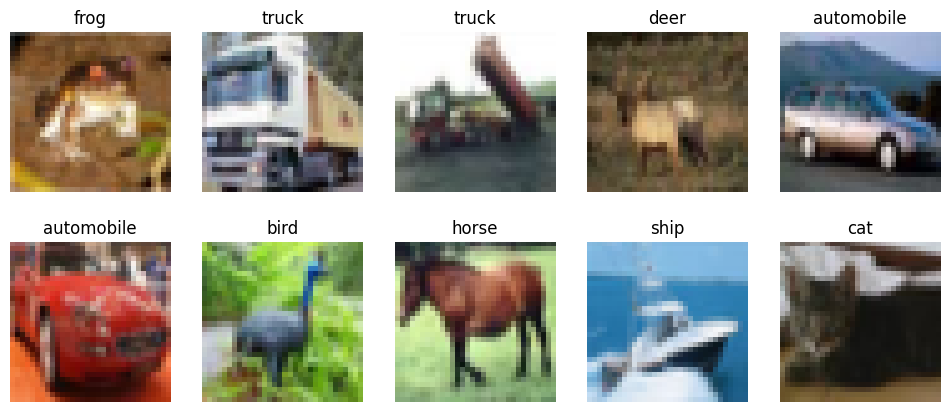

In [6]:
plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train_full[i])
    plt.title(class_names[y_train_full[i]])
    plt.axis('off')
plt.show()

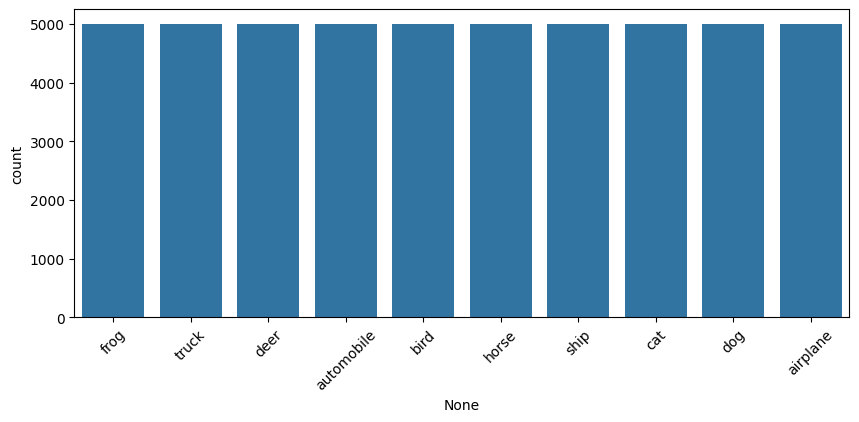

In [7]:
plt.figure(figsize=(10, 4))
sns.countplot(x=pd.Series(y_train_full).map(dict(enumerate(class_names))))
plt.xticks(rotation=45)
plt.show()

# ***Data Preprocessing***

In [8]:
X_train_full = X_train_full.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

In [9]:
X_train, X_val, y_train, y_val = train_test_split(X_train_full, y_train_full, test_size=0.1, stratify=y_train_full, random_state=SEED)
print(X_train.shape, X_val.shape, X_test.shape)

(45000, 32, 32, 3) (5000, 32, 32, 3) (10000, 32, 32, 3)


# ***Baseline CNN***

In [10]:
baseline_model = keras.Sequential([
    layers.Input(shape=(32, 32, 3)),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])

baseline_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
baseline_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       147,520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 167,562 (654.54 KB)

 Trainable params: 167,562 (654.54 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

baseline_history = baseline_model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=30, batch_size=64, callbacks=[early_stop], verbose=2)

Epoch 1/30
704/704 - 14s - 20ms/step - accuracy: 0.4611 - loss: 1.4962 - val_accuracy: 0.5494 - val_loss: 1.2815
Epoch 2/30
704/704 - 3s - 4ms/step - accuracy: 0.5905 - loss: 1.1682 - val_accuracy: 0.6262 - val_loss: 1.0857
Epoch 3/30
704/704 - 3s - 4ms/step - accuracy: 0.6396 - loss: 1.0379 - val_accuracy: 0.6544 - val_loss: 1.0117
Epoch 4/30
704/704 - 3s - 4ms/step - accuracy: 0.6708 - loss: 0.9479 - val_accuracy: 0.6616 - val_loss: 0.9826
Epoch 5/30
704/704 - 3s - 5ms/step - accuracy: 0.6972 - loss: 0.8778 - val_accuracy: 0.6744 - val_loss: 0.9510
Epoch 6/30
704/704 - 3s - 4ms/step - accuracy: 0.7190 - loss: 0.8157 - val_accuracy: 0.6698 - val_loss: 0.9713
Epoch 7/30
704/704 - 3s - 4ms/step - accuracy: 0.7375 - loss: 0.7614 - val_accuracy: 0.6746 - val_loss: 0.9690
Epoch 8/30
704/704 - 3s - 4ms/step - accuracy: 0.7548 - loss: 0.7147 - val_accuracy: 0.6730 - val_loss: 0.9980
Epoch 9/30
704/704 - 3s - 4ms/step - accuracy: 0.7702 - loss: 0.6714 - val_accuracy: 0.6660 - val_loss: 1.0202

# ***Improved CNN***

In [12]:
cnn_model = keras.Sequential([
    layers.Input(shape=(32, 32, 3)),
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.05),

    layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    layers.Conv2D(128, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(10, activation='softmax')
])

cnn_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
cnn_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 32, 32, 3)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 357,706 (1.36 MB)

 Trainable params: 357,258 (1.36 MB)

 Non-trainable params: 448 (1.75 KB)

In [13]:
early_stop = EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True)

cnn_history = cnn_model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=50, batch_size=64, callbacks=[early_stop], verbose=2)

Epoch 1/50
704/704 - 16s - 22ms/step - accuracy: 0.3117 - loss: 1.8846 - val_accuracy: 0.4230 - val_loss: 1.5786
Epoch 2/50
704/704 - 8s - 12ms/step - accuracy: 0.4167 - loss: 1.5880 - val_accuracy: 0.5282 - val_loss: 1.3219
Epoch 3/50
704/704 - 8s - 11ms/step - accuracy: 0.4802 - loss: 1.4464 - val_accuracy: 0.5768 - val_loss: 1.1914
Epoch 4/50
704/704 - 8s - 12ms/step - accuracy: 0.5206 - loss: 1.3381 - val_accuracy: 0.6392 - val_loss: 1.0063
Epoch 5/50
704/704 - 8s - 12ms/step - accuracy: 0.5543 - loss: 1.2597 - val_accuracy: 0.6048 - val_loss: 1.1135
Epoch 6/50
704/704 - 8s - 11ms/step - accuracy: 0.5771 - loss: 1.2027 - val_accuracy: 0.6110 - val_loss: 1.0745
Epoch 7/50
704/704 - 10s - 15ms/step - accuracy: 0.5998 - loss: 1.1491 - val_accuracy: 0.6588 - val_loss: 0.9838
Epoch 8/50
704/704 - 9s - 12ms/step - accuracy: 0.6132 - loss: 1.1159 - val_accuracy: 0.6882 - val_loss: 0.9002
Epoch 9/50
704/704 - 8s - 12ms/step - accuracy: 0.6257 - loss: 1.0746 - val_accuracy: 0.6762 - val_los

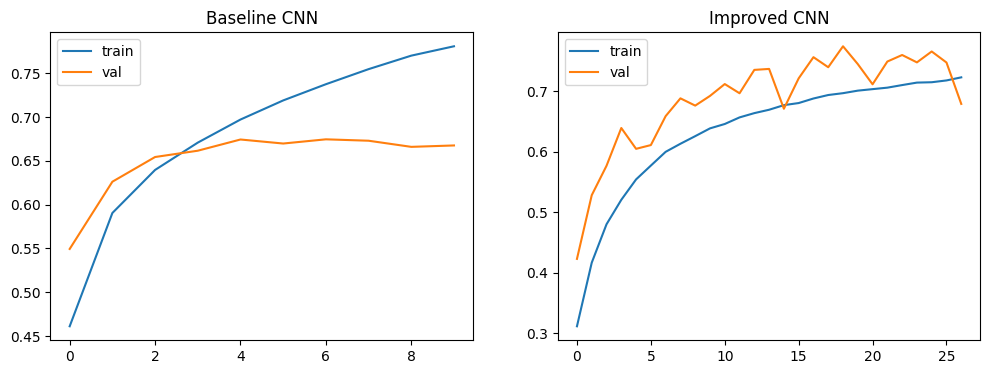

In [14]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(baseline_history.history['accuracy'], label='train')
plt.plot(baseline_history.history['val_accuracy'], label='val')
plt.title('Baseline CNN')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(cnn_history.history['accuracy'], label='train')
plt.plot(cnn_history.history['val_accuracy'], label='val')
plt.title('Improved CNN')
plt.legend()

plt.show()

# ***Evaluating the CNN***

In [15]:
y_pred_cnn = np.argmax(cnn_model.predict(X_test, verbose=0), axis=1)
print(classification_report(y_test, y_pred_cnn, target_names=class_names))

              precision    recall  f1-score   support

    airplane       0.72      0.83      0.77      1000
  automobile       0.92      0.87      0.89      1000
        bird       0.69      0.65      0.67      1000
         cat       0.55      0.64      0.59      1000
        deer       0.81      0.59      0.68      1000
         dog       0.71      0.63      0.67      1000
        frog       0.78      0.86      0.82      1000
       horse       0.76      0.84      0.80      1000
        ship       0.88      0.87      0.87      1000
       truck       0.87      0.85      0.86      1000

    accuracy                           0.76     10000
   macro avg       0.77      0.76      0.76     10000
weighted avg       0.77      0.76      0.76     10000



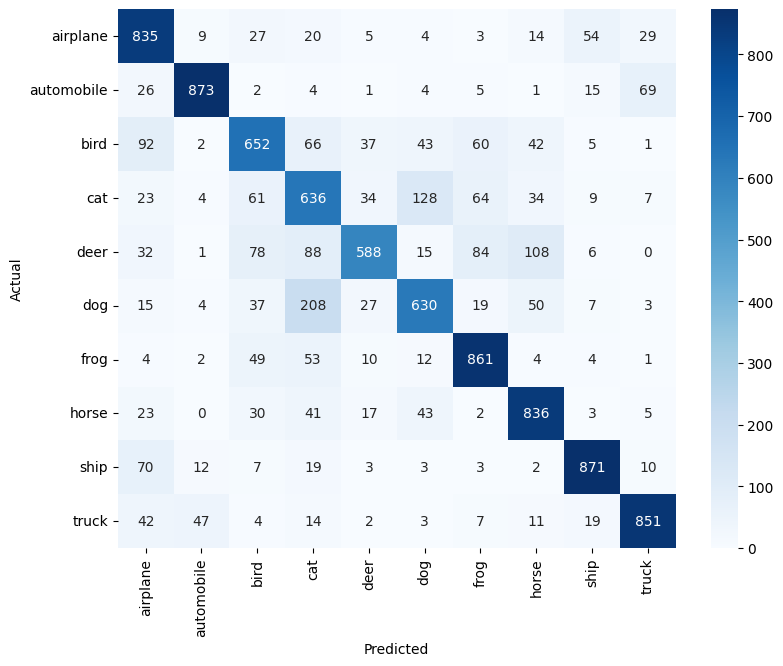

In [16]:
cm = confusion_matrix(y_test, y_pred_cnn)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

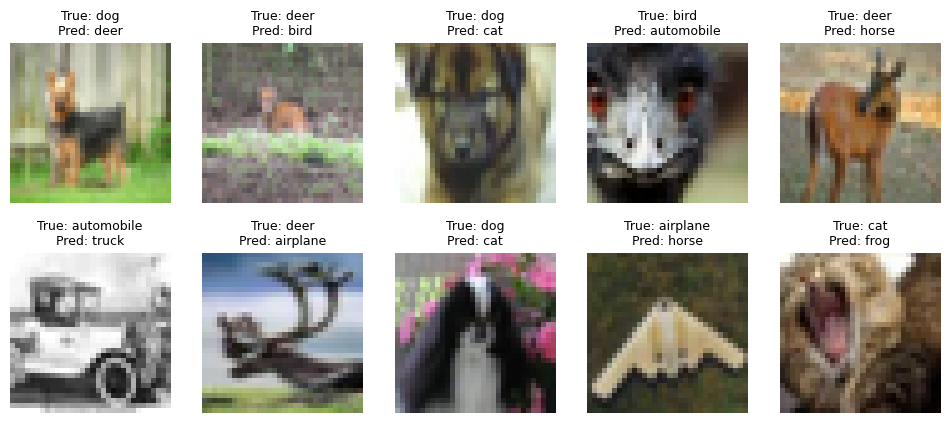

In [17]:
wrong = np.where(y_pred_cnn != y_test)[0]

plt.figure(figsize=(12, 5))
for i, idx in enumerate(wrong[:10]):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[idx])
    plt.title(f'True: {class_names[y_test[idx]]}\nPred: {class_names[y_pred_cnn[idx]]}', fontsize=9)
    plt.axis('off')
plt.show()

# ***Baseline vs Improved CNN***

In [18]:
y_pred_base = np.argmax(baseline_model.predict(X_test, verbose=0), axis=1)

results = []
for name, y_pred in [("Baseline CNN", y_pred_base), ("Improved CNN", y_pred_cnn)]:
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, average='macro'),
        "Recall": recall_score(y_test, y_pred, average='macro'),
        "F1": f1_score(y_test, y_pred, average='macro')
    })

results_df = pd.DataFrame(results)
results_df

,Model,Accuracy,Precision,Recall,F1
0,Baseline CNN,0.6707,0.678524,0.6707,0.669515
1,Improved CNN,0.7633,0.768448,0.7633,0.762592


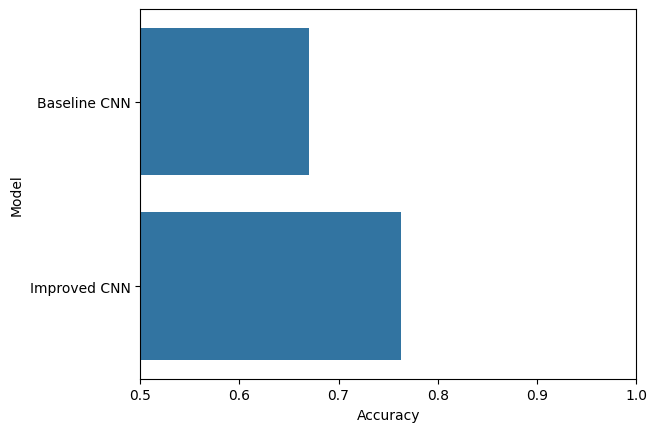

In [19]:
sns.barplot(x="Accuracy", y="Model", data=results_df)
plt.xlim(0.5, 1.0)
plt.show()

# ***Saving the Model***

In [20]:
cnn_model.save("cifar10_cnn.keras")
joblib.dump(class_names, "class_names.pkl")

['class_names.pkl']